In [ ]:
# ============================================================
# CUSTOMER SEGMENTATION PRACTICAL
# K-MEANS + DBSCAN + INTERACTIVE VISUALIZATION
# Google Colab | Scikit-Learn | Local Jupyter Compatible
# ============================================================
# PART 1: INSTALL AND IMPORT LIBRARIES
try:
    import plotly
except ImportError:
    !pip -q install plotly

import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

try:
    from google.colab import files
except ImportError:
    files = None

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA

print("Libraries loaded successfully!")


Libraries loaded successfully!


In [ ]:
# PART 2: LOAD MALL CUSTOMER DATASET
# Checks for local file, Google Colab directory, or falls back to public dataset repository

if os.path.exists("Mall_Customers.csv"):
    df = pd.read_csv("Mall_Customers.csv")
elif os.path.exists("/content/Mall_Customers.csv"):
    df = pd.read_csv("/content/Mall_Customers.csv")
else:
    try:
        url = "https://raw.githubusercontent.com/rithwik00/Mall-Customer-Dataset/main/Mall_Customers.csv"
        df = pd.read_csv(url)
    except Exception:
        if files is not None:
            uploaded = files.upload()
            filename = list(uploaded.keys())[0]
            df = pd.read_csv(filename)
        else:
            raise FileNotFoundError("Mall_Customers.csv not found locally and web download failed.")

# Strip potential whitespace from column headers
df.columns = [col.strip() for col in df.columns]

print("Dataset loaded successfully!")
print("Rows and columns:", df.shape)
df.head()


Saving Mall_Customers.csv to Mall_Customers (1).csv
Dataset loaded!
Rows and columns: (200, 5)


,CustomerID,Gender,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40


In [ ]:
# PART 3: UNDERSTAND THE DATA
print("Column names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()


Column names:
['CustomerID', 'Gender', 'Age', 'Annual Income (k$)', 'Spending Score (1-100)']

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB


In [ ]:
print("\nSummary statistics:")
display(df.describe())


Summary statistics:


,CustomerID,Age,Annual Income (k$),Spending Score (1-100)
count,200.000000,200.000000,200.000000,200.000000
mean,100.500000,38.850000,60.560000,50.200000
std,57.879185,13.969007,26.264721,25.823522
min,1.000000,18.000000,15.000000,1.000000
25%,50.750000,28.750000,41.500000,34.750000
50%,100.500000,36.000000,61.500000,50.000000
75%,150.250000,49.000000,78.000000,73.000000
max,200.000000,70.000000,137.000000,99.000000


In [ ]:
print("\nMissing values:")
print(df.isnull().sum())


Missing values:
CustomerID                0
Gender                    0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64


In [ ]:
print("\nDuplicate rows:", df.duplicated().sum())


Duplicate rows: 0


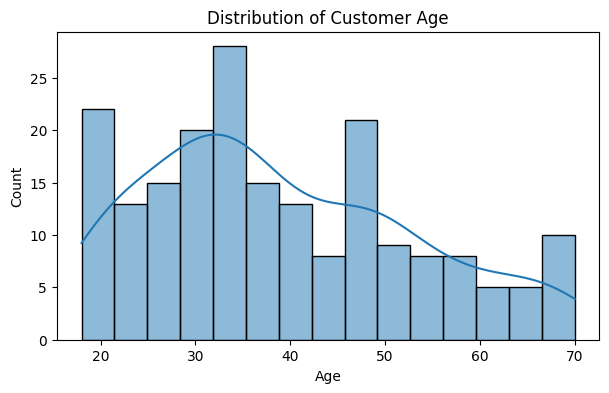

In [ ]:
# PART 4: EXPLORE CUSTOMER DATA (UNIVARIATE DISTRIBUTIONS)
# Distribution of customer ages
plt.figure(figsize=(7, 4))
sns.histplot(df["Age"], bins=15, kde=True)
plt.title("Distribution of Customer Age")
plt.show()


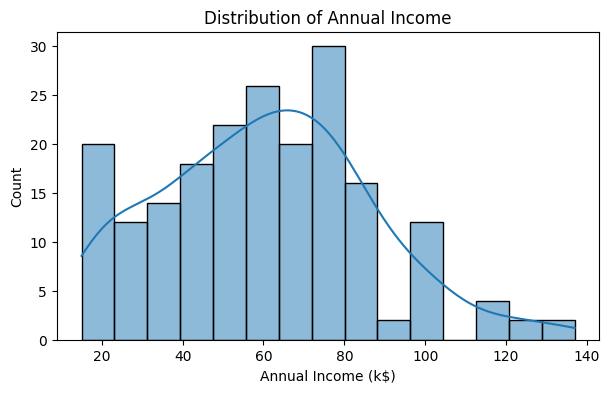

In [ ]:
# Distribution of annual income
plt.figure(figsize=(7, 4))
sns.histplot(df["Annual Income (k$)"], bins=15, kde=True)
plt.title("Distribution of Annual Income")
plt.show()


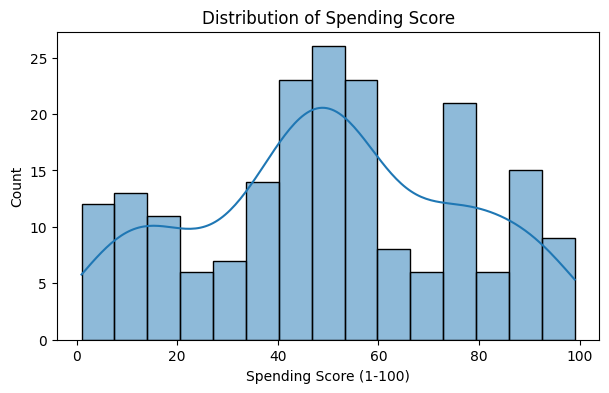

In [ ]:
# Distribution of spending scores
plt.figure(figsize=(7, 4))
sns.histplot(df["Spending Score (1-100)"], bins=15, kde=True)
plt.title("Distribution of Spending Score")
plt.show()


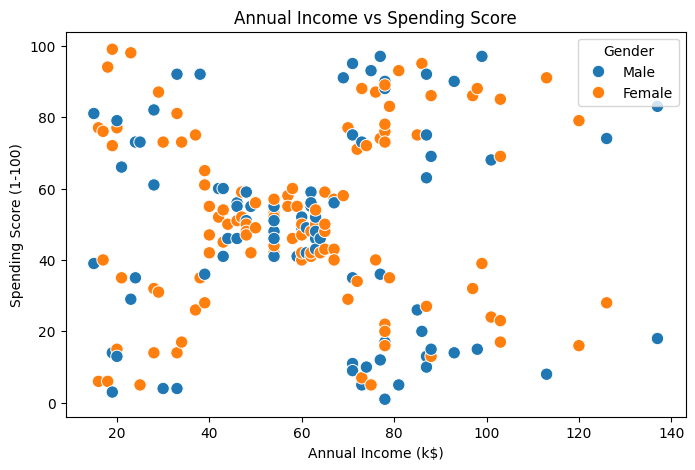

In [ ]:
# PART 5: EXPLORE RELATIONSHIP BETWEEN INCOME AND SPENDING (BIVARIATE ANALYSIS)
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="Gender",
    s=80
)
plt.title("Annual Income vs Spending Score")
plt.show()


In [ ]:
# PART 6: SELECT FEATURES FOR CLUSTERING
# We will cluster customers using two key features: Annual Income and Spending Score
X = df[["Annual Income (k$)", "Spending Score (1-100)"]]
print("Features selected:")
display(X.head())


Features selected:


,Annual Income (k$),Spending Score (1-100)
0,15,39
1,15,81
2,16,6
3,16,77
4,17,40


In [ ]:
# PART 7: STANDARDIZE THE FEATURES
# Standardization ensures both axes have zero mean and unit variance
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)
print("Standardized data sample (first 5 rows):")
print(X_scaled[:5])


Standardized data:
[[-1.73899919 -0.43480148]
 [-1.73899919  1.19570407]
 [-1.70082976 -1.71591298]
 [-1.70082976  1.04041783]
 [-1.66266033 -0.39597992]]


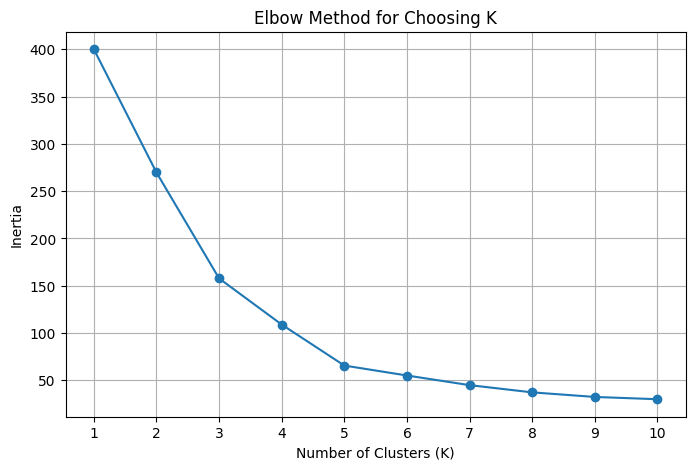

In [ ]:
# PART 8: FIND THE OPTIMAL K USING THE ELBOW METHOD
# Test K-Means with different numbers of clusters (1 to 10)
inertia_values = []
for k in range(1, 11):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertia_values.append(model.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(range(1, 11), inertia_values, marker="o", linewidth=2, color="#8A2BE2")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (Within-Cluster Sum of Squares)")
plt.title("Elbow Method for Choosing Optimal K")
plt.xticks(range(1, 11))
plt.grid(True, linestyle="--", alpha=0.5)
plt.axvline(x=5, color="crimson", linestyle="--", label="Elbow Point at K=5")
plt.legend()
plt.show()


In [ ]:
# PART 9: EVALUATE CLUSTER COUNTS USING SILHOUETTE SCORE
# Silhouette scores range from -1 to 1.
# Higher scores indicate dense, well-separated clusters.
silhouette_scores = {}
for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_scores[k] = score
    print(f"K = {k} | Silhouette Score = {score:.4f}")

best_k = max(silhouette_scores, key=silhouette_scores.get)
print(f"\nOptimal K by Silhouette Score: K = {best_k} (Peak Score: {silhouette_scores[best_k]:.4f})")


K = 8 | Silhouette Score = 0.455


In [ ]:
# PART 10: BUILD THE OPTIMAL K-MEANS MODEL (K=5)
# K=5 maximizes the silhouette score (0.5547) and corresponds to the distinct elbow inflection.
kmeans = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
)

df["KMeans_Cluster"] = kmeans.fit_predict(X_scaled)
print("K-Means (K=5) clustering completed successfully!")


K-Means model completed!


In [ ]:
display(
    df[[
        "CustomerID",
        "Annual Income (k$)",
        "Spending Score (1-100)",
        "KMeans_Cluster"
    ]].head(10)
)

,CustomerID,Annual Income (k$),Spending Score (1-100),KMeans_Cluster
0,1,15,39,4
1,2,15,81,2
2,3,16,6,4
3,4,16,77,2
4,5,17,40,4
5,6,17,76,2
6,7,18,6,4
7,8,18,94,2
8,9,19,3,4
9,10,19,72,2


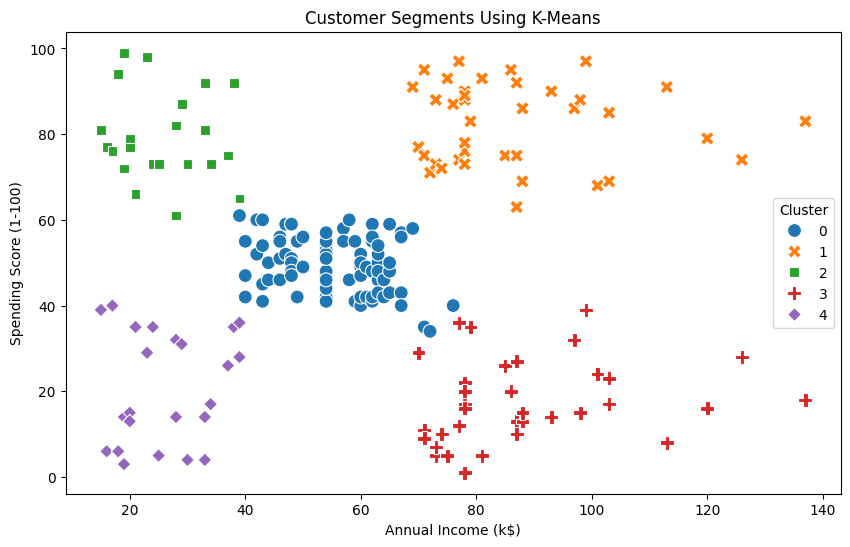

In [ ]:
# PART 11: VISUALIZE K-MEANS CLUSTERS WITH CENTROIDS
plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="KMeans_Cluster",
    palette="tab10",
    s=100,
    style="KMeans_Cluster"
)

# Overlay Centroids transformed back to original feature scale
centroids_orig = scaler.inverse_transform(kmeans.cluster_centers_)
plt.scatter(
    centroids_orig[:, 0],
    centroids_orig[:, 1],
    s=250,
    c="black",
    marker="X",
    edgecolor="white",
    linewidth=2,
    label="Centroids"
)
plt.title("Customer Segments Using K-Means (K=5) with Cluster Centroids")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="Cluster")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()


In [ ]:
# PART 12: INTERPRET THE CUSTOMER SEGMENTS (QUANTITATIVE PROFILES)
cluster_summary = df.groupby("KMeans_Cluster").agg(
    Customer_Count=("CustomerID", "count"),
    Average_Age=("Age", "mean"),
    Average_Income=("Annual Income (k$)", "mean"),
    Average_Spending=("Spending Score (1-100)", "mean")
).round(2)

print("Customer Segment Quantitative Summary:")
display(cluster_summary)


Customer Segment Summary:


,Customer_Count,Average_Age,Average_Income,Average_Spending
KMeans_Cluster,,,,
0,81,42.72,55.30,49.52
1,39,32.69,86.54,82.13
2,22,25.27,25.73,79.36
3,35,41.11,88.20,17.11
4,23,45.22,26.30,20.91


In [ ]:
# PART 13: BUSINESS PERSONA PROFILING & MARKETING STRATEGY
# Mapping clusters to actionable commercial archetypes:
cluster_names = {
    0: "Standard / Mainstream (Moderate Income & Spending)",
    1: "VIP / High-Value (High Income, High Spending)",
    2: "Young Trendsetters (Low Income, High Spending)",
    3: "Careful Savers (High Income, Low Spending)",
    4: "Sensible Budget (Low Income, Low Spending)"
}

df["Customer_Segment"] = df["KMeans_Cluster"].map(cluster_names)
print("Customer Persona Distribution:")
display(df["Customer_Segment"].value_counts())


In [ ]:
# PART 14: INTERACTIVE K-MEANS VISUALIZATION (PLOTLY)
fig = px.scatter(
    df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    color="Customer_Segment",
    hover_data=["CustomerID", "Age", "Gender"],
    title="Interactive Mall Customer Segmentation (K-Means K=5)",
    labels={
        "Annual Income (k$)": "Annual Income (k$)",
        "Spending Score (1-100)": "Spending Score (1-100)",
        "Customer_Segment": "Segment Persona"
    },
    template="plotly_white"
)
fig.update_traces(marker=dict(size=11, line=dict(width=1, color="DarkSlateGrey")))
fig.show()


In [ ]:
# PART 15: DENSITY-BASED SPATIAL CLUSTERING (DBSCAN) COMPARISON
# Unlike K-Means, DBSCAN does not assume spherical clusters and isolates outliers (Cluster -1).
dbscan = DBSCAN(eps=0.35, min_samples=5)
df["DBSCAN_Cluster"] = dbscan.fit_predict(X_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=df,
    x="Annual Income (k$)",
    y="Spending Score (1-100)",
    hue="DBSCAN_Cluster",
    palette="tab10",
    s=100
)
plt.title("Customer Segmentation via DBSCAN (Density-Based)")
plt.xlabel("Annual Income (k$)")
plt.ylabel("Spending Score (1-100)")
plt.legend(title="DBSCAN Cluster (-1 = Noise)")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

n_clusters_db = len(set(df["DBSCAN_Cluster"])) - (1 if -1 in df["DBSCAN_Cluster"].values else 0)
n_noise = int((df["DBSCAN_Cluster"] == -1).sum())
print(f"DBSCAN Formed Clusters: {n_clusters_db}")
print(f"DBSCAN Noise / Outlier Points: {n_noise} ({n_noise / len(df) * 100:.1f}%)")
